In [3]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from functools import partial

In [4]:
pm_seed = 4
num_samples = 128
i_list = range(num_samples)
save_dirs = ['../../exp/vol_jwst%d_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.001/%d'%(pm_seed, i) for i in i_list]

wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_4.npy').transpose(1, 2, 0)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4.npy')[:, 20:89, -69:] .transpose(1, 2, 0)
ddpm_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples.npy')[:, :, 20:89, -69:].transpose(0, 2, 3, 1)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]

daps_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_nops.npy')[:, 20:89, -69:] .transpose(1, 2, 0)

res = 69

def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)
densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

density_gt = jnp.load(save_dirs[-1] + '/../density_gt.p').reshape(res, res, 20)


CUDA backend failed to initialize: jaxlib/cuda/versions_helpers.cc:98: operation cuInit(0) failed: CUDA_ERROR_NO_DEVICE (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [5]:
print(density_gt.shape, densities_arr.shape, ddpm_samples.shape)

(69, 69, 20) (128, 69, 69, 20) (128, 69, 69, 20)


In [6]:
density_gt_vec = density_gt.reshape(1, -1)
neur_samples_vec = densities_arr.reshape(num_samples, -1)
ddpm_samples_vec = ddpm_samples.reshape(num_samples, -1)

neur_mae = jnp.abs(density_gt_vec - neur_samples_vec).mean(0)
ddpm_mae = jnp.abs(density_gt_vec - ddpm_samples_vec).mean(0)

neur_std = jnp.std(neur_samples_vec, axis=0)
ddpm_std = jnp.std(ddpm_samples_vec, axis=0)

print(neur_mae.shape, neur_std.shape)

(95220,) (95220,)


In [7]:
import numpy as np

def bin_xy_tail(x, y, nbins=100, cover=0.99, return_std=False):
    """
    Bin (x, y) into nbins where the first nbins-1 bins are equal-width over [xmin, q_cover],
    and the last bin catches all x > q_cover (upper-tail outliers).

    Returns:
      centers: (nbins,) x-positions to plot (last center placed just right of q_cover)
      y_mean : (nbins,) mean(y) per bin (NaN where count==0)
      counts : (nbins,) number of points per bin
      y_std  : (nbins,) std(y) per bin (unbiased; NaN where count<2) if return_std=True
    """
    x = np.asarray(x)
    y = np.asarray(y)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    if x.size == 0:
        raise ValueError("No finite (x, y) pairs.")

    cover = float(cover)
    if not (0 < cover <= 1):
        raise ValueError("cover must be in (0, 1].")
    if nbins < 2:
        raise ValueError("nbins must be >= 2 to allocate a tail bin.")

    xmin = x.min()
    q_cover = np.quantile(x, cover) if cover < 1.0 else x.max()

    # If cover collapses (all x identical), fall back to single-width bins + tail
    span = max(q_cover - xmin, 0.0)
    main_bins = nbins - 1  # number of equal-width bins before the tail
    binw = span / main_bins if main_bins > 0 else 0.0

    # Edges for the main region [xmin, q_cover]
    if span == 0.0:
        edges = np.linspace(xmin, xmin + 1.0, main_bins + 1)  # arbitrary unit span
        binw = edges[1] - edges[0]
        q_cover = edges[-1]
    else:
        edges = np.linspace(xmin, q_cover, main_bins + 1)

    # Compute bin indices:
    # - main region: 0..(nbins-2)
    # - tail (x > q_cover): nbins-1
    idx = np.empty_like(x, dtype=int)
    in_main = x <= q_cover
    # floor((x - xmin)/(q_cover - xmin) * main_bins), clamp to [0, main_bins-1]
    if span > 0:
        t = (x[in_main] - xmin) / span
        idx[in_main] = np.clip(np.floor(t * main_bins).astype(int), 0, main_bins - 1)
    else:
        idx[in_main] = 0  # everything identical goes to first bin
    idx[~in_main] = nbins - 1  # tail bin

    # Aggregates
    counts = np.bincount(idx, minlength=nbins)
    sum_y  = np.bincount(idx, weights=y, minlength=nbins)
    y_mean = np.divide(sum_y, counts, out=np.full(nbins, np.nan), where=counts > 0)

    # Bin centers (last center placed just to the right of q_cover)
    centers = np.empty(nbins, dtype=float)
    centers[:-1] = 0.5 * (edges[:-1] + edges[1:]) if main_bins > 0 else np.array([])
    centers[-1]  = q_cover + 0.5 * binw if binw > 0 else q_cover + 0.5

    if not return_std:
        return centers, y_mean, counts

    sum_y2 = np.bincount(idx, weights=y * y, minlength=nbins)
    Ey2 = np.divide(sum_y2, counts, out=np.full(nbins, np.nan), where=counts > 0)
    var = Ey2 - y_mean**2
    with np.errstate(invalid="ignore"):
        var_unbiased = var * counts / (counts - 1)
    y_std = np.full(nbins, np.nan)
    ok = counts >= 2
    y_std[ok] = np.sqrt(np.maximum(var_unbiased[ok], 0.0))

    return centers, y_mean, counts, y_std


In [8]:
xc_ddpm, ym_ddpm, cnt_ddpm, ys_ddpm = bin_xy_tail(ddpm_std, ddpm_mae, nbins=50, cover=0.99, return_std=True)
xc_neur, ym_neur, cnt_neur, ys_neur = bin_xy_tail(neur_std, neur_mae, nbins=50, cover=0.99, return_std=True)

In [9]:
prop_ddpm = cnt_ddpm / (20 * 69 * 69)
prop_neur = cnt_neur / (20 * 69 * 69)

In [10]:
r_ddpm = np.corrcoef(xc_ddpm, ym_ddpm)[0,1]
r_neur = np.corrcoef(xc_neur, ym_neur)[0,1]
print(r_ddpm)
print(r_neur)

0.8996147031270666
0.9162868147409273


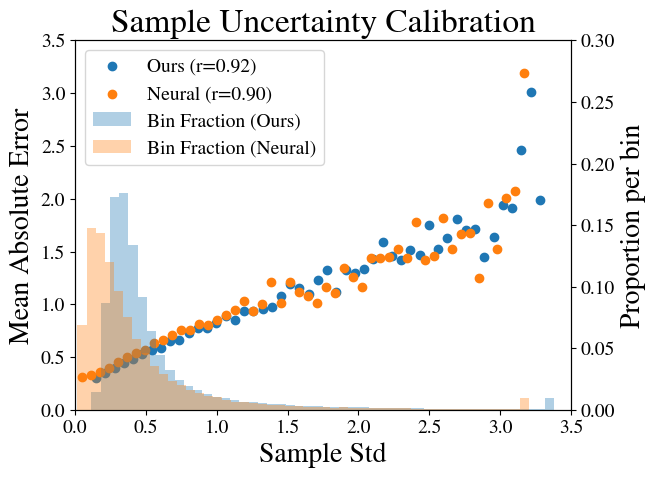

In [13]:
import matplotlib as mpl

mpl.rcParams.update({
    "axes.unicode_minus": False,
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif", "Times New Roman", "Times"],
    "mathtext.fontset": "stix",   # STIX math
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def centers_to_widths(c):
    c = np.asarray(c)
    if c.ndim != 1 or c.size < 1:
        raise ValueError("centers must be a 1D array with at least 1 element")
    if c.size == 1:
        w = np.array([1.0])  # arbitrary fallback
        return c.astype(float), w
    edges = np.empty(c.size + 1, dtype=float)
    edges[1:-1] = 0.5 * (c[:-1] + c[1:])
    edges[0]    = c[0] - 0.5 * (c[1] - c[0])
    edges[-1]   = c[-1] + 0.5 * (c[-1] - c[-2])
    widths = np.diff(edges)
    return c.astype(float), widths

# --- your existing plot ---
fig, ax = plt.subplots()
ax.scatter(xc_ddpm, ym_ddpm, label='Ours (r=0.92)')
ax.scatter(xc_neur, ym_neur, label='Neural (r=0.90)')
# ax.plot([0, 3.5], [0, 3.5], linestyle='dashed', label='y=x')
ax.set_xlim(0, 3.5)
ax.set_ylim(0, 3.5)
ax.set_title('Sample Uncertainty Calibration', fontsize=24)
ax.set_xlabel('Sample Std', fontsize=20)
ax.set_ylabel('Mean Absolute Error', fontsize=20)

# --- right y-axis with proportion bars using your centers ---
ax2 = ax.twinx()
ax2.set_ylim(0, 0.3)
ax2.set_ylabel('Proportion per bin', fontsize=20)
ax2.yaxis.set_label_position("right")
ax2.yaxis.tick_right()

# Build bar positions & widths from provided centers
c1, w1 = centers_to_widths(xc_ddpm)
c2, w2 = centers_to_widths(xc_neur)

# If centers align, offset side-by-side; otherwise draw centered
side_by_side = (len(c1) == len(c2)) and np.allclose(c1, c2, rtol=1e-6, atol=1e-12)
if side_by_side:
    ax2.bar(c1 - 0.25 * w1, prop_ddpm, width=0.5 * w1, alpha=0.35,
            label='Ours (prop)', align='center', edgecolor='none')
    ax2.bar(c2 + 0.25 * w2, prop_neur, width=0.5 * w2, alpha=0.35,
            label='Neural (prop)', align='center', edgecolor='none')
else:
    ax2.bar(c1, prop_ddpm, width=w1, alpha=0.35, label='Bin Fraction (Ours)',
            align='center', edgecolor='none')
    ax2.bar(c2, prop_neur, width=w2, alpha=0.35, label='Bin Fraction (Neural)',
            align='center', edgecolor='none')

# Combined legend
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=14)
# ax2.legend(h2, l2, loc='upper right')

plt.savefig('../jwst_figs/calibration.pdf', bbox_inches='tight')
plt.show()


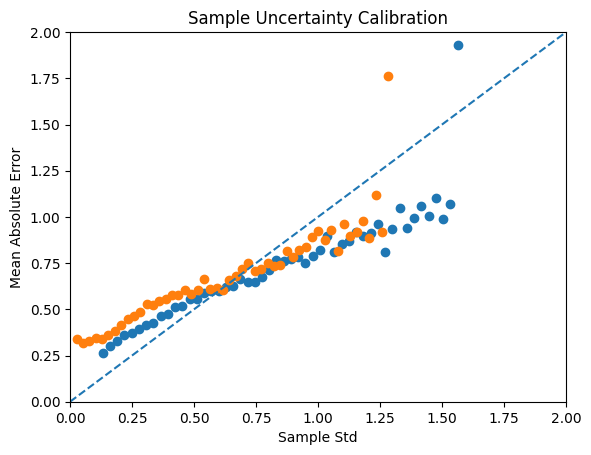

In [29]:
plt.scatter(xc_ddpm, ym_ddpm, label='Ours')
plt.scatter(xc_neur, ym_neur, label='Neural')
plt.plot([0, 2], [0, 2], linestyle='dashed', label='y=x')
plt.xlim((0, 2))
plt.ylim((0, 2))
plt.title('Sample Uncertainty Calibration')
plt.xlabel('Sample Std')
plt.ylabel('Mean Absolute Error')
plt.show()